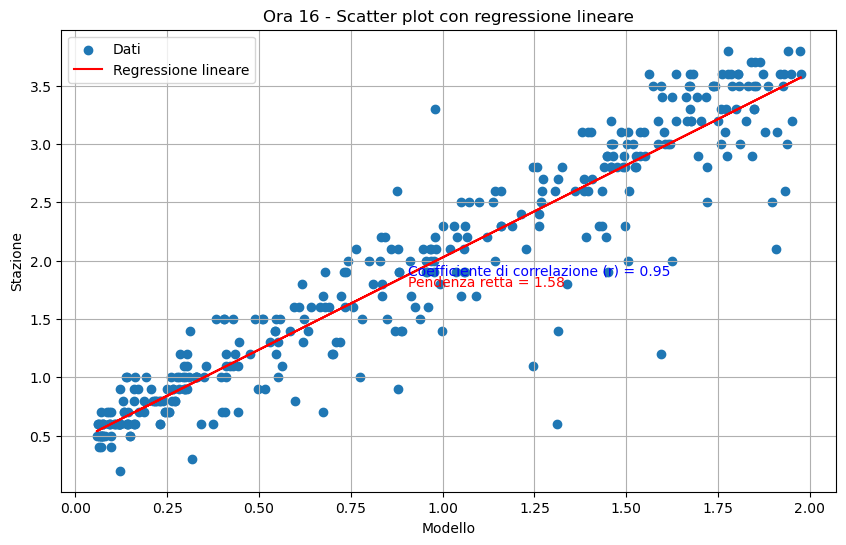

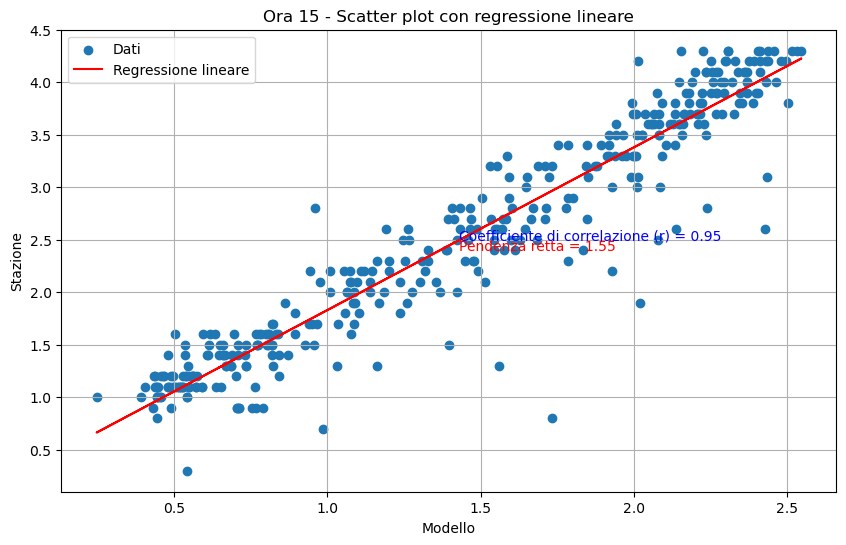

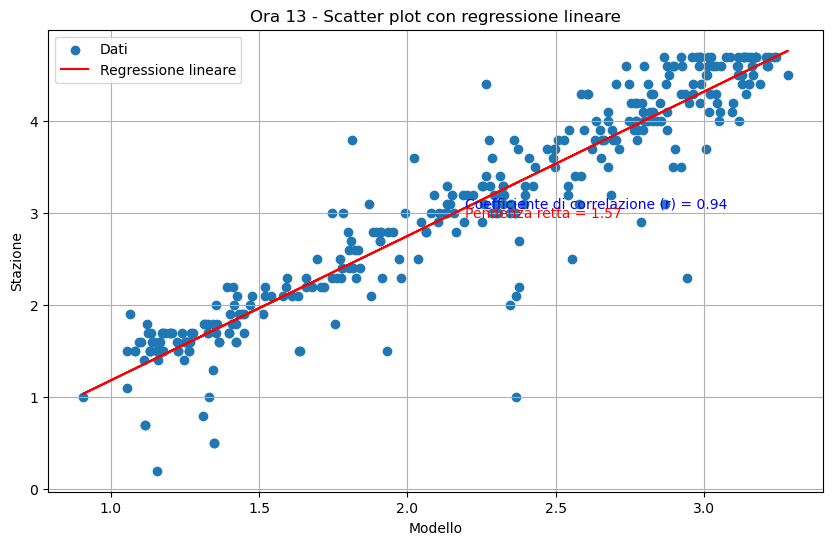

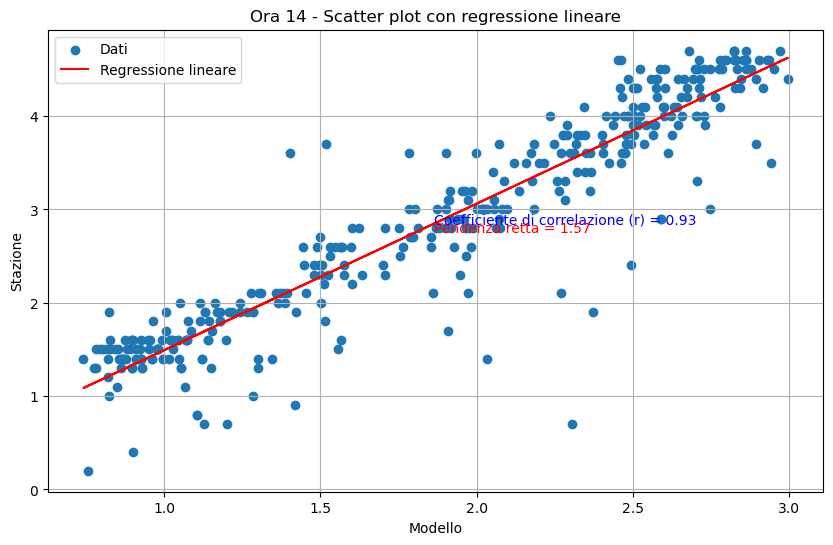

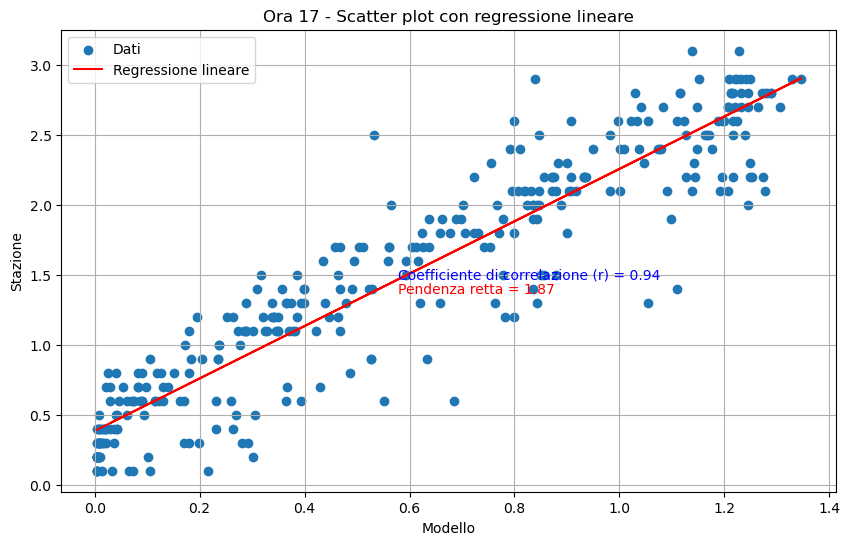

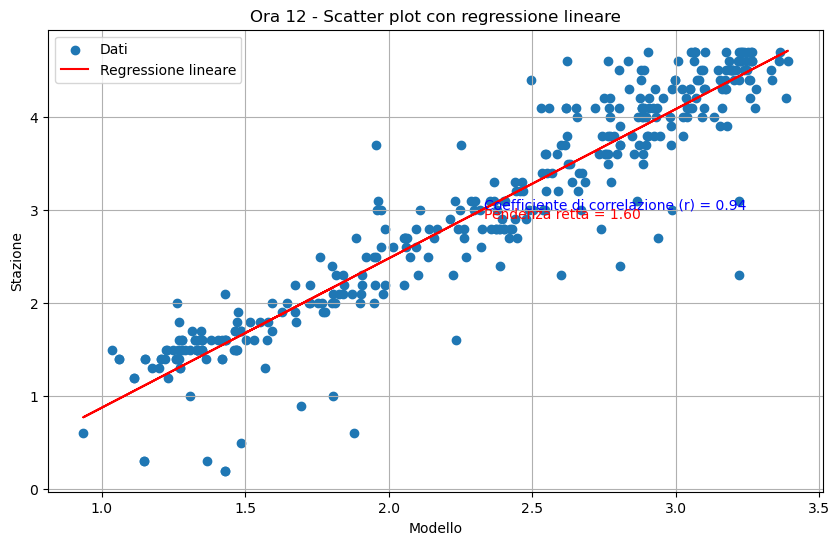

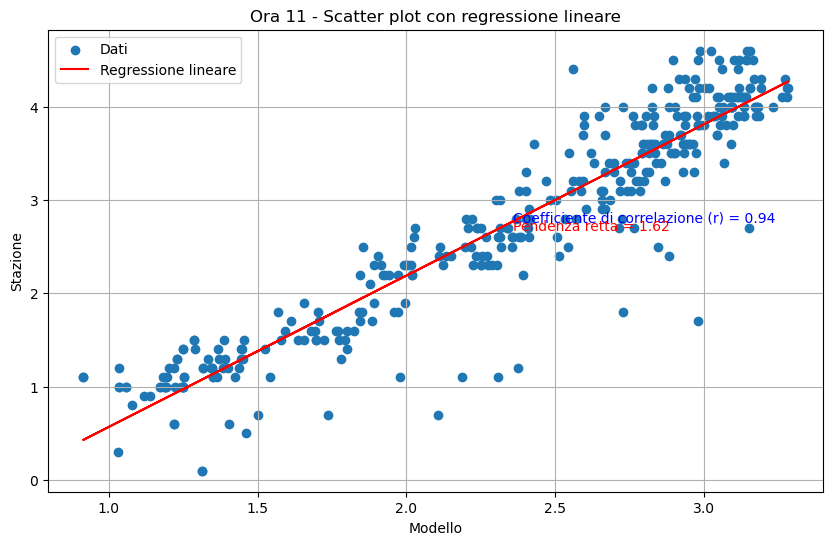

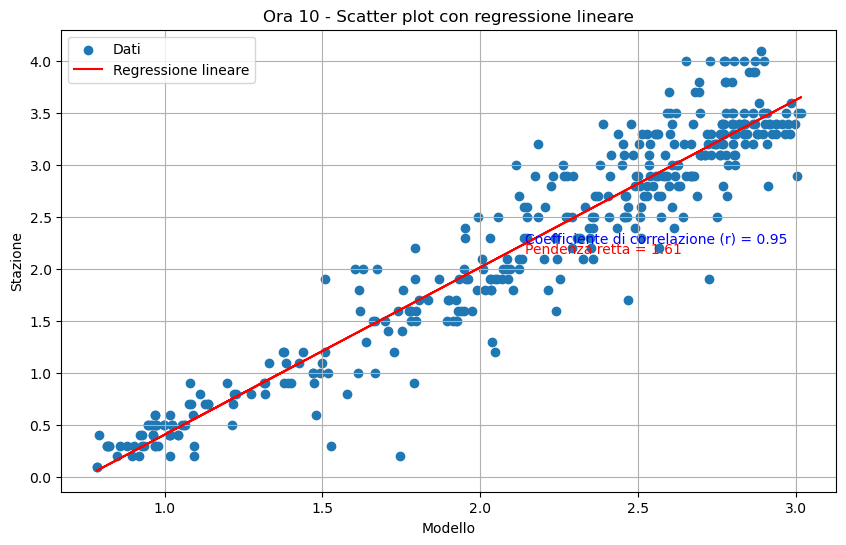

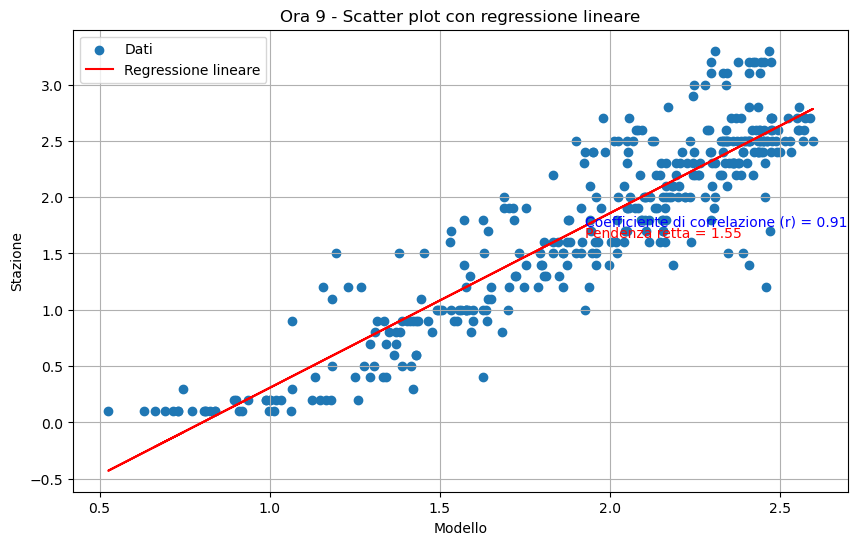

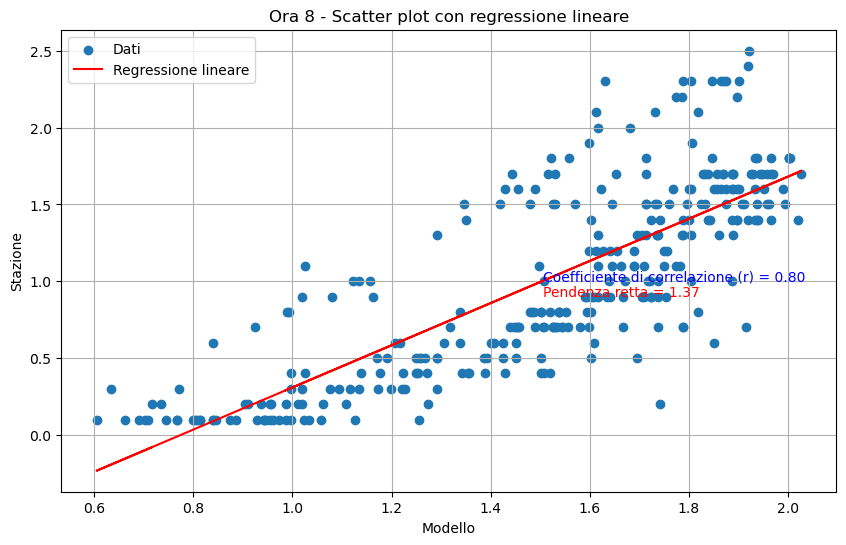

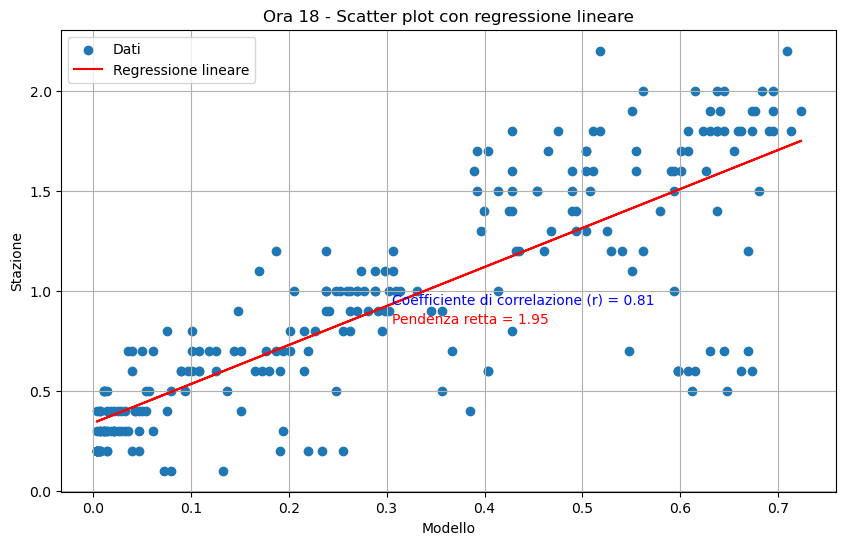

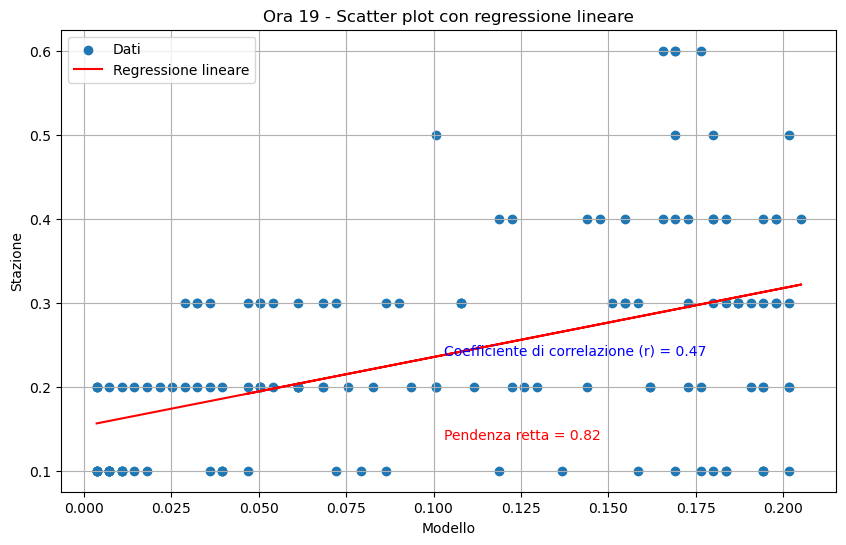

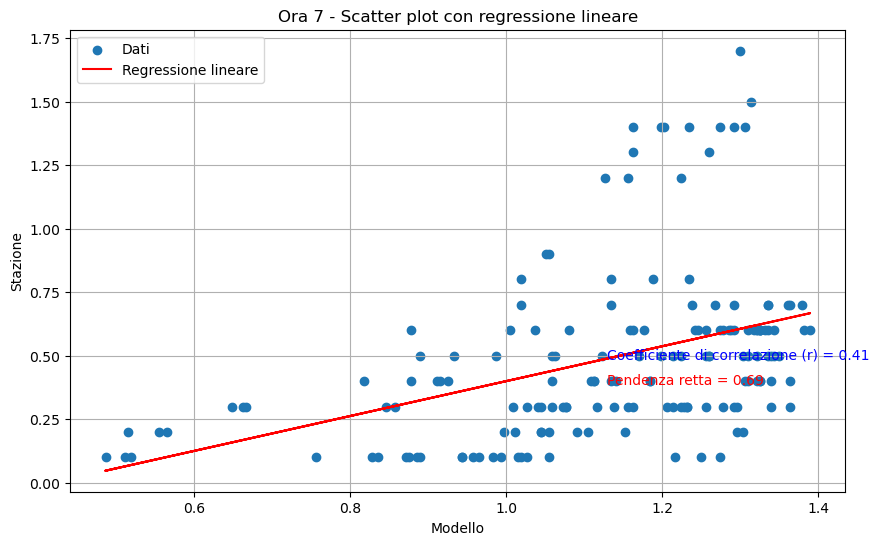

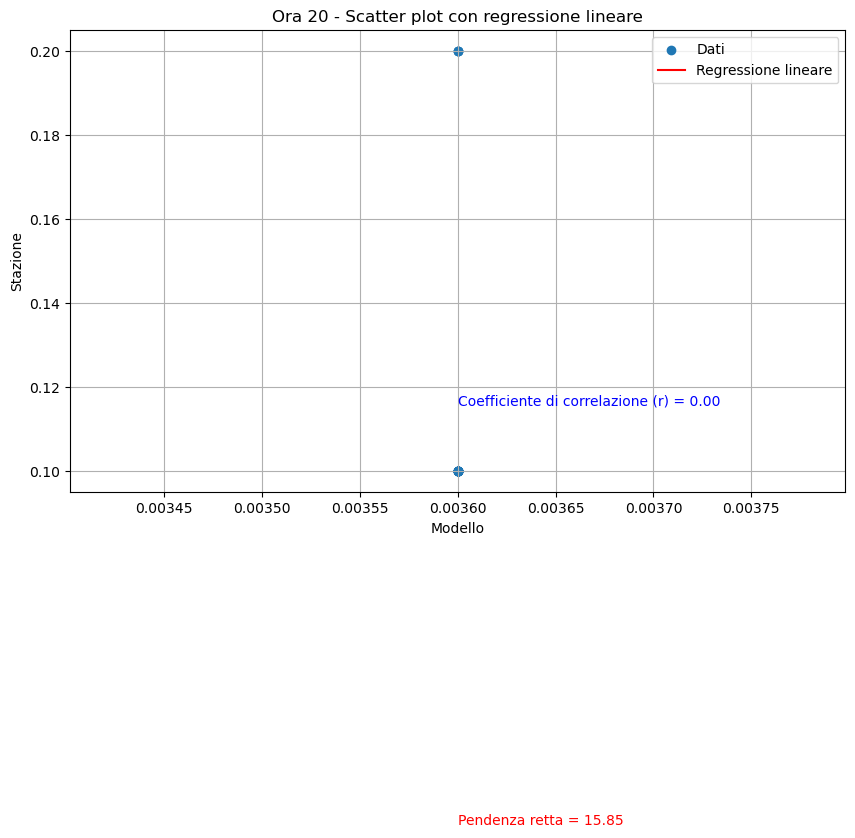

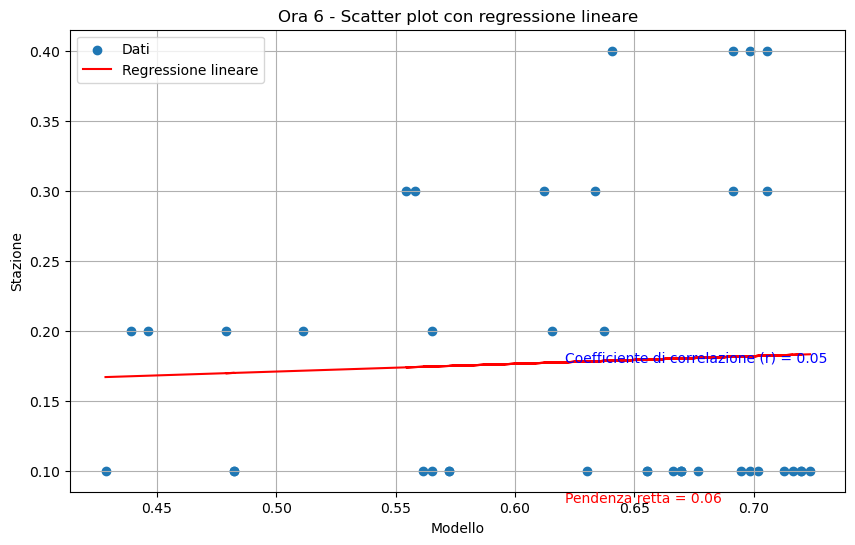

C:\Users\vitto\anaconda3\Lib\site-packages\numpy\lib\function_base.py:2889: RuntimeWarning: Degrees of freedom <= 0 for slice
  c = cov(x, y, rowvar, dtype=dtype)
C:\Users\vitto\anaconda3\Lib\site-packages\numpy\lib\function_base.py:2748: RuntimeWarning: divide by zero encountered in divide
  c *= np.true_divide(1, fact)
C:\Users\vitto\anaconda3\Lib\site-packages\numpy\lib\function_base.py:2748: RuntimeWarning: invalid value encountered in multiply
  c *= np.true_divide(1, fact)


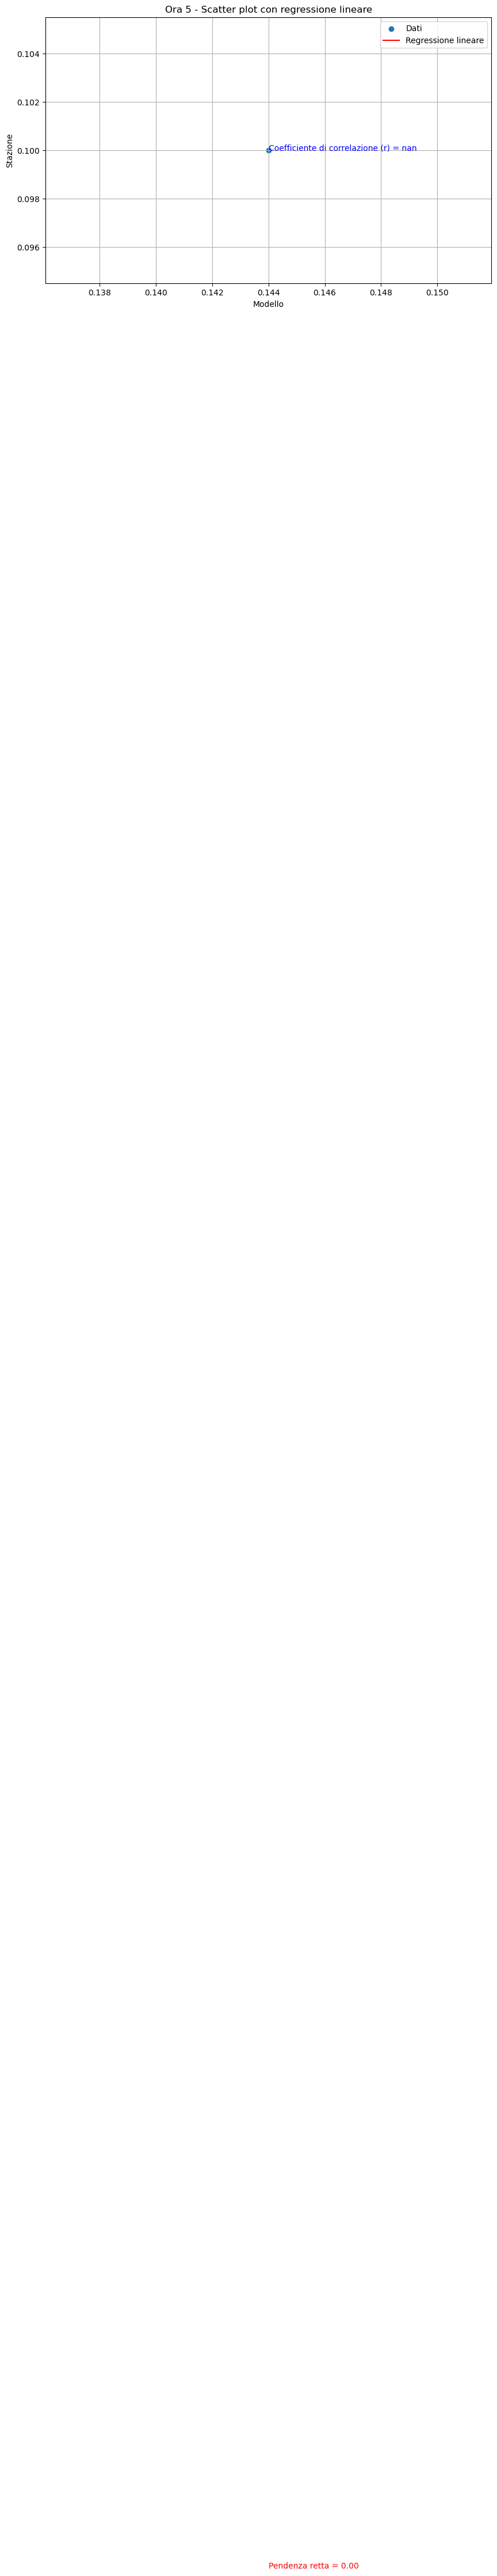

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import sqlite3
from sklearn.linear_model import LinearRegression

# Connessione al database SQLite
conn = sqlite3.connect(r'C:\Users\vitto\Desktop\VB\UNIVERSITÀ\STAGE\RADIAZIONE\DETERIORAMENTO_DATO\STAZIONE83\83_ORARIA.db')
cursor = conn.cursor()

# Query per selezionare i dati dalla tabella
query = "SELECT data, ora, stazione, modello FROM TabellaAccorpata"
df = pd.read_sql_query(query, conn)

# Chiusura della connessione al database
conn.close()

# Converti la colonna 'data' in datetime
df['data'] = pd.to_datetime(df['data'], format='%d/%m/%Y')

# Filtra i dati per le righe in cui entrambe 'stazione' e 'modello' sono diversi da 0
df_filtered = df[(df['stazione'] != 0) & (df['modello'] != 0)]

# Ottieni le ore uniche
unique_hours = df_filtered['ora'].unique()

# Crea un grafico per ogni ora
for hour in unique_hours:
    df_hour = df_filtered[df_filtered['ora'] == hour]
    
    
    x = df_hour['modello'].values.reshape(-1, 1)
    y = df_hour['stazione'].values

    # Regressione lineare
    model = LinearRegression().fit(x, y)
    y_pred = model.predict(x)

    # Coefficiente di correlazione
    r = np.corrcoef(x.squeeze(), y)[0, 1]
       # Pendenza della retta
    slope = model.coef_[0]

    
    plt.figure(figsize=(10, 6))
    plt.scatter(x, y, label='Dati')
    plt.plot(x, y_pred, color='red', label='Regressione lineare')
    plt.xlabel('Modello')
    plt.ylabel('Stazione')
    plt.title(f'Ora {hour} - Scatter plot con regressione lineare')
    plt.text(x.mean(), y.mean(), f'Coefficiente di correlazione (r) = {r:.2f}', fontsize=10, color='blue')
    plt.text(x.mean(), y.mean() - 0.1, f'Pendenza retta = {slope:.2f}', fontsize=10, color='red')
    plt.legend()
    plt.grid(True)
    plt.show()
